# `vkastro` Demo — 400,000 Real ESA Gaia DR3 Stars on Vulkan GPU

Astropy-style GPU astrophysics using **`vkastro`** + **`vkpandas`** + **`vkshader` (2D & 3D)** + **`vkplot`** + **`vkpanel`** on **400,000 real stars** from the European Space Agency's **Gaia Data Release 3**:
1. **GPU Coordinate Transforms**: `SkyCoord(ra, dec, distance).galactic` and 3D Galactocentric `(X, Y, Z)` parsecs.
2. **Hertzsprung–Russell (Color–Magnitude) Diagram**: Main Sequence, Red Giant Branch, and White Dwarfs shaded via GPU `eq_hist`.
3. **All-Sky Hammer–Aitoff Milky Way Map** (`vkastro.aitoff_projection`).
4. **Interactive 3D Solar Neighborhood Fly-Through** (`vkshader.interact_3d` in deep space, colored by stellar spectral temperature).
5. **GPU Cone Search** around the **Pleiades (M45)** + **`FlatLambdaCDM` Cosmology**.

In [1]:
import sys, time
from pathlib import Path
_root = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import vknumpy as vnp
import vkpandas as vpd
import vkastro as vka
import vkshader as vks
import vkholoviews as hv
import vkpanel as pn
import vkplot.vkpandas  # registers .vkplot

gaia_path = Path.home() / ".cache/vkdata/astro/gaia_dr3_400k.parq"
t0 = time.perf_counter()
stars = vpd.read_parquet(gaia_path)

# GPU photometry & 3D Galactic coordinates
dist_pc = vka.parallax_to_distance(stars["parallax"], unit="pc")
abs_g   = vka.absolute_magnitude(stars["phot_g_mean_mag"], dist_pc)
teff_k  = vka.bp_rp_to_temperature(stars["bp_rp"])

sc = vka.SkyCoord(stars["ra"], stars["dec"], distance=dist_pc, frame="icrs")
gal = sc.galactic
gx, gy, gz = gal.cartesian()
ax, ay = vka.aitoff_projection(gal.ra, gal.dec)

stars["dist_pc"]   = dist_pc
stars["abs_mag"]   = abs_g
stars["neg_abs_g"] = -abs_g  # brighter stars at top of HR diagram
stars["teff_k"]    = teff_k
stars["gal_l"]     = gal.ra
stars["gal_b"]     = gal.dec
stars["x_pc"]      = gx
stars["y_pc"]      = gy
stars["z_pc"]      = gz
stars["aitoff_x"]  = ax
stars["aitoff_y"]  = ay

# Spectral color class from Gaia (BP - RP): 0=Blue O/B, 1=White A/F, 2=Yellow G, 3=Orange K, 4=Red M
bprp_np = stars["bp_rp"].to_numpy()
spec_cls = np.digitize(bprp_np, bins=[0.5, 1.0, 1.6, 2.3]).astype(np.int32)
stars["spec_class"] = vnp.array(spec_cls, dtype=np.int32)

print(f"Loaded & transformed {len(stars):,} ESA Gaia DR3 stars on Vulkan GPU in {(time.perf_counter()-t0)*1000:.1f} ms")

ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


Loaded & transformed 400,000 ESA Gaia DR3 stars on Vulkan GPU in 476.9 ms


## 1. Hertzsprung–Russell (Color–Magnitude) Diagram & All-Sky Galactic Map

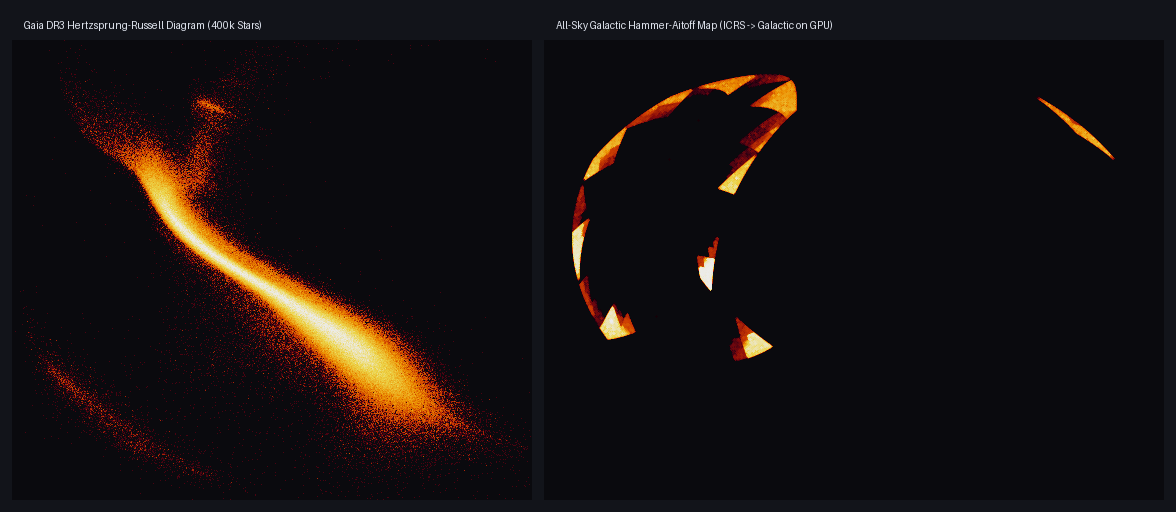

In [2]:
hr_diag = stars.vkplot.points(
    "bp_rp", "neg_abs_g", how="eq_hist",
    width=520, height=460, xlim=(-0.6, 4.2), ylim=(-16.0, 2.0),
    title="Gaia DR3 Hertzsprung-Russell Diagram (400k Stars)",
)
sky_map = stars.vkplot.points(
    "aitoff_x", "aitoff_y", how="eq_hist",
    width=620, height=460, xlim=(-2.9, 2.9), ylim=(-1.5, 1.5),
    title="All-Sky Galactic Hammer-Aitoff Map (ICRS -> Galactic on GPU)",
)
(hr_diag + sky_map).cols(2)

## 2. Interactive 3D Solar Neighborhood Fly-Through (`vkshader.interact_3d`)

Real 3D Galactic Cartesian positions `(X, Y, Z)` in **parsecs** (1 parsec = 3.26 light-years) around the Sun:
- **Drag**: 3D Orbit | **Shift+Drag / Right-Drag**: Fly/Pan | **Scroll**: Zoom | **Double-click**: Reset
- Colored by **Spectral Class** (Blue O/B → White A/F → Yellow G → Orange K → Red M dwarfs) or **Galactic Height Z (Fire)**!

In [3]:
regions_3d = {
    "Solar Neighborhood (±500 pc)": ((-500.0, 500.0), (-500.0, 500.0)),
    "Local Bubble (±200 pc)":       ((-200.0, 200.0), (-200.0, 200.0)),
    "Near Sun (±100 pc)":           ((-100.0, 100.0), (-100.0, 100.0)),
}
color_modes_3d = {
    "Spectral Color (Blue O/B -> Red M)": ("spec_class", ["#66b3ff", "#eef6ff", "#ffe680", "#ff9933", "#ff4d4d"]),
    "Galactic Z Height (Fire)": (None, None),
}

vks.interact_3d(
    stars, "x_pc", "y_pc", "z_pc",
    width=840, height=540,
    z_range=(-300.0, 300.0),
    kind="points",
    color_modes=color_modes_3d,
    regions=regions_3d,
    basemap=None,
    z_scale=0.80,
);

## 3. GPU Cone Search (Pleiades M45) & `FlatLambdaCDM` Cosmology

GPU cone_search(Pleiades M45, r=3 deg): 0 stars found in 31.68 ms


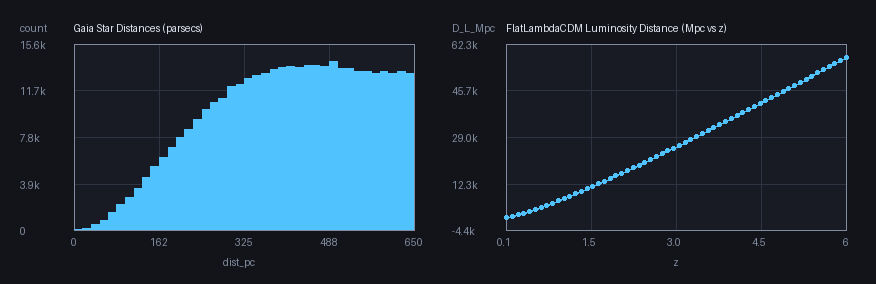

In [4]:
# Cone search within 3 deg of the Pleiades open cluster (RA=56.75, Dec=24.12)
t0 = time.perf_counter()
m45_mask = sc.cone_search(56.75, 24.12, radius_deg=3.0)
m45 = stars[m45_mask]
print(f"GPU cone_search(Pleiades M45, r=3 deg): {len(m45):,} stars found in {(time.perf_counter()-t0)*1000:.2f} ms")

# FlatLambdaCDM Luminosity Distance curve from z = 0.05 .. 6.0 on GPU
cosmo = vka.FlatLambdaCDM(H0=70.0, Om0=0.3)
z_grid = vnp.linspace(0.05, 6.0, 60, dtype=np.float32)
dl_mpc = cosmo.luminosity_distance(z_grid)
cosmo_df = vpd.DataFrame({"z": z_grid, "D_L_Mpc": dl_mpc})

(
    stars.vkplot.hist("dist_pc", bins=40, range=(0, 650), width=420, height=260, title="Gaia Star Distances (parsecs)")
    + cosmo_df.vkplot.line("z", "D_L_Mpc", width=420, height=260, title="FlatLambdaCDM Luminosity Distance (Mpc vs z)")
).cols(2)